### Resampling Exercise
Preston Stover - BERN02 - 29.09.26

In [131]:
import matplotlib.pyplot as plt
import csv
import numpy as np
import math

# seed
rng = np.random.default_rng(seed=6)

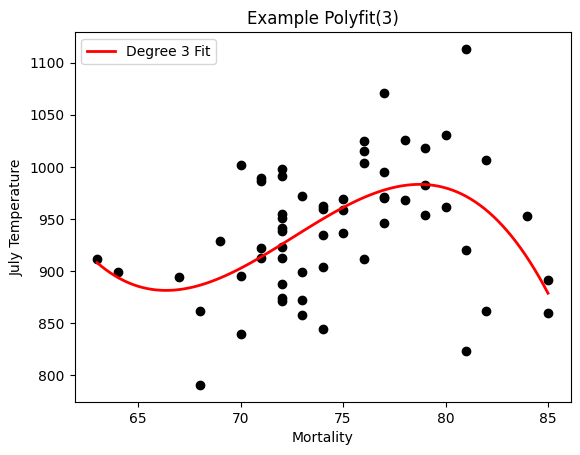

In [132]:
# Read variable data to lists
x, y = [], []
with open("bern02_class_git/Labs/pollution_cleaneddata.csv", mode="r") as file:

    ''' Turn rows of csv into Python dictionaries. Top row are keys and each 
    row below have data appended to each key.
    '''
    var_Dicts = csv.DictReader(file)
    for row in var_Dicts:
        # response variable: MORT - Total age-adjusted mortality rate per 100,000
        y.append(float(row["MORT"]))
        # predictor variable: POOR - % of families with income < $3000
        x.append(float(row["JULT"]))

# polynomial fit series:
reg = np.polynomial.Polynomial.fit(x,y,3)
# generate smooth x-values across the range of your data
x_line = np.linspace(min(x), max(x), 100)
# eval fitted polynomial at those x-values
y_line = reg(x_line)
# Look at the data to understand it better
plt.scatter(x,y,color='black',)
plt.plot(x_line, y_line, color="red", linewidth=2, label="Degree 3 Fit")
plt.title('Example Polyfit(3)')
plt.xlabel('Mortality')
plt.ylabel('July Temperature')
plt.legend()
plt.show()



In [133]:
# split data into two equal sets
x_arr, y_arr = np.array(x), np.array(y)
train_ratio = 0.5
split_idx = int(len(x_arr) * train_ratio)

# generate a random permutation of indices
shuffled_indices = rng.permutation(len(x_arr))

# Split indices into train and test sets
train_idx = shuffled_indices[:split_idx]
test_idx = shuffled_indices[split_idx:]
# Apply indexed masks to both arrays simultaneously
x_train, y_train = x_arr[train_idx], y_arr[train_idx]
x_test, y_test = x_arr[test_idx], y_arr[test_idx]


In [134]:
# MSE function:
def mse(y, y_pred):
    return np.mean((y - y_pred)**2)

# dicts to store prediction data and MSEs
y_train_pred_dict = {}
mse_dict = {}
test_mse_dict = {} 

p_deg = [1,2,3,4]
for p in p_deg:
    reg = np.polynomial.Polynomial.fit(x_train, y_train, p)
    # generate predicted values from regression
    y_pred = reg(x_train)
    # store predictions in dictionary
    y_train_pred_dict[p] = y_pred
    mse_dict[p] = mse(y_train, y_pred)
    test_mse_dict[p] = mse(y_test, reg(x_test))

# results
for p, err in mse_dict.items():
    print(f"Degree {p} Training MSE: {err:.4f} | Test MSE: {test_mse_dict[p]:.4f}")

Degree 1 Training MSE: 3889.6701 | Test MSE: 3508.7425
Degree 2 Training MSE: 2985.9404 | Test MSE: 5759.4881
Degree 3 Training MSE: 2605.4827 | Test MSE: 3372.9521
Degree 4 Training MSE: 2602.4678 | Test MSE: 3398.4720


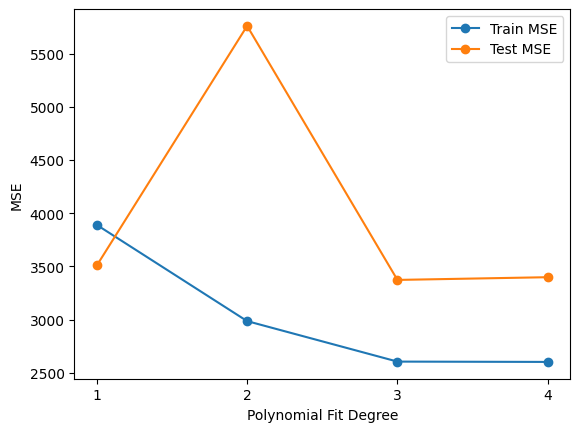

In [135]:
# visualization
plt.plot(p_deg, mse_dict.values(), marker="o", label="Train MSE")
plt.plot(p_deg, test_mse_dict.values(), marker="o", label="Test MSE")
plt.xlabel('Polynomial Fit Degree')
plt.xticks(p_deg)
plt.ylabel('MSE')
plt.legend()

6. Based on the MSE results plotted above, I would recommend using a 3rd degree polynomial fit to minimize the variance of new predictions and avoid overfitting.
7. After changing the random seed ten times, the overfitting of a 4th-degree polynomial regression occasionally causes the Test MSE value to become massive (>100 000). The 3rd-degree polynomial fit yields reliable low test error values.

In [136]:
# split indices into K=3 equal folds, works with remainders
k_folds_idx = np.array_split(shuffled_indices, 3)
p = 3 # 3rd-degree poly fit
folds_mse = []

for k in range(3):
    # hold out fold k:
    val_idx = k_folds_idx[k]
    # combine the remaining folds for training
    # hstack: horizontal stack sequence of arrays (combine remaining 2 k)
    train_idx = np.hstack([k_folds_idx[i] for i in range(3) if i != k])

    # subset the data
    x_train_k, y_train_k = x_arr[train_idx], y_arr[train_idx]
    x_val_k, y_val_k = x_arr[val_idx], y_arr[val_idx]

    # fit the degree-p polynomial on training folds
    reg_k = np.polynomial.Polynomial.fit(x_train_k, y_train_k, p)

    # Evaluate MSE on held-out validation fold
    val_pred = reg_k(x_val_k)
    val_mse = np.mean((y_val_k - val_pred) ** 2)
    folds_mse.append(val_mse)
    print(f"Fold {k+1} Validation MSE: {val_mse:.4f}")
print(f"\nMean CV MSE: {np.mean(folds_mse):.4f}")
print(f"Variance across folds: {np.var(folds_mse, ddof=1):.4f}")

Fold 1 Validation MSE: 2870.2664
Fold 2 Validation MSE: 4059.1759
Fold 3 Validation MSE: 2013.6267

Mean CV MSE: 2981.0230
Variance across folds: 1055268.1790


9. The results are similar across all ten random seeds chosen. The individual validation fitting data is 2/3 of the total data chosen,two of the three k-fold sets. This is reflected in the consistent cross-validation mean values across many seeds while each individual fold validation varies as the data used for the polynomial fit only represent a single set of 2/3 of data chosen, not the averaged results from each combination of 2/3 k-folds.

### Part 2 - Bootstrap Birds

In [137]:
# Read variable data to lists
x_list, y_list = [], []
with open("bern02_class_git/Labs/bird_count.csv", mode="r") as file:

    ''' Turn rows of csv into Python dictionaries. Top row are keys and each 
    row below have data appended to each key.
    '''
    var_Dicts = csv.DictReader(file)
    for row in var_Dicts:
        y_list.append(float(row["count"]))
        x_list.append(float(row["yr"]) - 2005.6923)

/var/folders/_d/zft0fndj7z3fdyqbny0sfsr00000gn/T/ipykernel_17237/3324748945.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


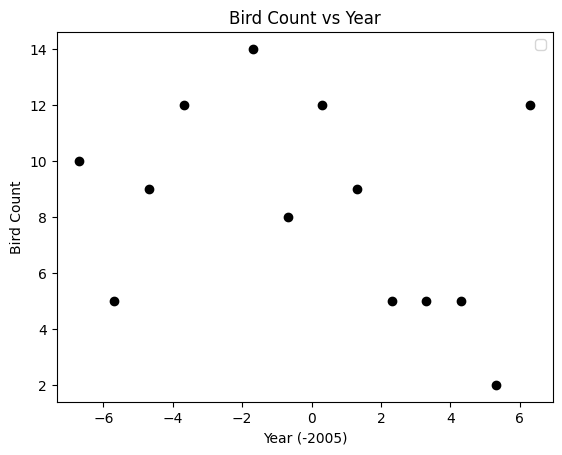

In [138]:
plt.scatter(x_list,y_list,color='black',)
plt.title('Bird Count vs Year')
plt.xlabel('Year (-2005)')
plt.ylabel('Bird Count')
plt.legend()
plt.show()

In [139]:
# setup arrays
x_arr = np.array(x_list)
y_arr = np.array(y_list)
N = len(x_arr)

# my Newton-Raphson code from previous assignment:
def fit_poisson(x_data, y_data, loops=16):
    b0 = 0.0
    b1 = 0.0

    for j in range(loops):
        g0 = 0.0
        g1 = 0.0
        h00 = 0.0
        h01 = 0.0
        h10 = 0.0
        h11 = 0.0

        for i in range(len(x_data)):
            lam = math.exp(b0 + b1 * x_data[i])

            # Gradient vector
            g0 += y_data[i] - lam
            g1 += x_data[i] * (y_data[i] - lam)

            # Hessian matrix
            h00 += -lam
            h01 += -x_data[i] * lam
            h10 += -x_data[i] * lam
            h11 += -(x_data[i] ** 2) * lam

        # 2x2 matrix inversion:
        determinate = (h00 * h11) - (h01 * h10)
        inv_h00 = h11 / determinate
        inv_h01 = -h01 / determinate
        inv_h10 = -h10 / determinate
        inv_h11 = h00 / determinate

        # Update parameter vector: -= H^(-1) * g
        b0 -= inv_h00 * g0 + inv_h01 * g1
        b1 -= inv_h10 * g0 + inv_h11 * g1

    return b0, b1


# Original point estimate for full data set
b0_hat, b1_hat = fit_poisson(x_arr, y_arr)
print(f"Estimate -> b0: {b0_hat:.5f}, b1: {b1_hat:.5f}")

Estimate -> b0: 2.10821, b1: -0.03244


In [144]:
# sample many slopes B_(1,B) and calc standard error:
B = 1000  # bootstrap reps
b1_bootstraps = []

for _ in range(B):
    # 1. Sample indices WITH replacement using your initialized `rng`
    boot_idx = rng.choice(N, size=N, replace=True)

    # 2. Subset your data using the sampled indices
    x_boot = x_arr[boot_idx]
    y_boot = y_arr[boot_idx]

    # 3. Fit Poisson model on bootstrap sample and extract b1
    _, b1_b = fit_poisson(x_boot, y_boot)
    b1_bootstraps.append(b1_b)

# standard Error of b1
se_b1 = np.std(b1_bootstraps, ddof=1)

print(f"Bootstrap Mean of b1: {np.mean(b1_bootstraps):.5f}")
print(f"Estimated SE(b1):      {se_b1:.5f}")



Bootstrap Mean of b1: -0.03650
Estimated SE(b1):      0.03418


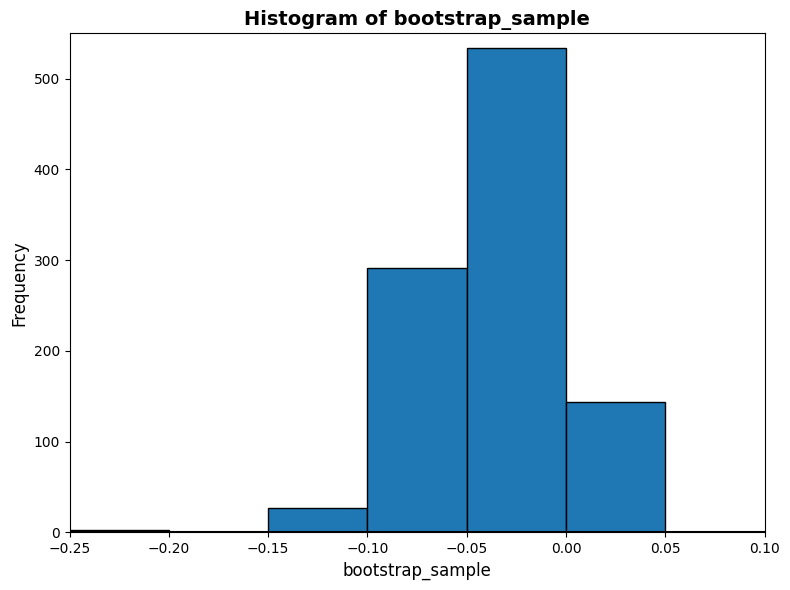

In [142]:
import matplotlib.pyplot as plt

# Set bin edges
bins = [-0.25, -0.20, -0.15, -0.10, -0.05, 0.00, 0.05, 0.10]

plt.figure(figsize=(8, 6))
plt.hist(b1_bootstraps, bins=bins, edgecolor="black", linewidth=1)

plt.title("Histogram of bootstrap_sample", fontsize=14, fontweight="bold")
plt.xlabel("bootstrap_sample", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.xlim(-0.25, 0.10)
plt.xticks([-0.25, -0.20, -0.15, -0.10, -0.05, 0.00, 0.05, 0.10])
plt.ylim(0, 550)

plt.axhline(0, color="black", linewidth=1.5)

plt.tight_layout()
plt.show()

12. When taking the standard deviation of the bootstrap sample of the slope parameter I get 0.034821, see code cell above histogram code cell.